# Credit Card Fraud Detection: Three Video Approaches, Three Datasets, One Project

This notebook extends the project (see `CreditCardDetection_Project.ipynb` for the 2023-dataset analysis) with the approaches and datasets from three YouTube tutorials, trained and evaluated under one consistent protocol.

| Source | Approach described | Dataset | What was done here |
|---|---|---|---|
| **Video 1**: JP Infotech, *Credit Card Fraud Detection Using Machine Learning* | Random Forest and XGBoost with SMOTE-family over-sampling (SMOTE, ADASYN, Borderline-SMOTE, KMeans-SMOTE), also MLP and LSTM, in a Flask app | **Not named** in the description. Its IEEE base paper uses a proprietary 145-million-row dataset from the Brazilian fintech Stone, which is not public | Methods replicated on the ULB dataset. Not replicated: "AGSS" (no standard implementation, not described), LSTM, the Flask/SQLite app |
| **Video 2**: Siddhardhan, *Project 10. Credit Card Fraud Detection* | Logistic Regression | **ULB** credit card fraud (Kaggle `mlg-ulb/creditcardfraud`) | Replicated on the identical dataset (OpenML mirror, MD5-verified) |
| **Video 3**: Onur Baltaci, *Fraud Detection Using Machine Learning* | Full fraud-detection project | **PaySim-style** transactions (Kaggle `amanalisiddiqui/fraud-detection-dataset`, about 6.36M rows) | Pipeline written and smoke-tested on a synthetic stand-in. **Not run on the real data**: Kaggle requires a login to download it |
| Original project | RF / XGBoost / Logistic Regression | Credit Card Fraud Detection Dataset **2023** | Existing notebook, plus compact saved models |

**How the replication was done.** I could read each video's title and description but not watch the videos, so "replica" means *the approach the description states, run on the dataset it names* (or, for video 1, on the ULB data). Video 2's description confirms Logistic Regression on the ULB data; under-sampling to a 50/50 sample is the common recipe for that dataset and is what is used here.

**Evaluation protocol (identical for every model).** One stratified 80/20 split (seed 42). Every resampler is fitted on the training split only. All models are scored on the same untouched, naturally imbalanced test split. PR-AUC is the headline metric; accuracy is shown only to illustrate why it misleads.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd()
U = json.load(open(ROOT / "results/ulb_results.json"))
CV = json.load(open(ROOT / "results/ulb_cv_results.json"))
X23 = json.load(open(ROOT / "results/cc2023_results.json"))
XD = json.load(open(ROOT / "results/cross_dataset_results.json"))
P = np.load(ROOT / "results/ulb_test_probas.npz")
y_test, amount_test = P["y_test"], P["amount"]
print("ULB test split:", len(y_test), "rows,", int(y_test.sum()), "frauds")

ULB test split: 56962 rows, 98 frauds


## 1. Two very different datasets

The ULB data is a real, naturally imbalanced card portfolio. The 2023 data is exactly balanced. Everything below depends on that difference.

In [2]:
from fraud_pipeline.data import load_ulb, load_cc2023
ulb, new = load_ulb(), load_cc2023()
V = [f"V{i}" for i in range(1, 29)]

def profile(d, name):
    return pd.Series({
        "rows": f"{len(d):,}",
        "fraud rows": f"{int(d.Class.sum()):,}",
        "fraud rate": f"{100 * d.Class.mean():.4f}%",
        "Amount mean / median": f"{d.Amount.mean():,.0f} / {d.Amount.median():,.0f}",
        "Amount skew": f"{d.Amount.skew():.2f}",
        "corr(Amount, Class)": f"{d.Amount.corr(d.Class):+.4f}",
        "Time column": "yes (48 h, in seconds)" if "Time" in d else "no",
        "V-column std range": f"{d[V].std().min():.2f} to {d[V].std().max():.2f}",
        "repeated V-vectors": f"{int(d.duplicated(subset=V).sum()):,}",
    }, name=name)

pd.concat([profile(ulb, "ULB (real)"), profile(new, "2023 dataset")], axis=1)

,ULB (real),2023 dataset
rows,"284,807","568,630"
fraud rows,492,"284,315"
fraud rate,0.1727%,50.0000%
Amount mean / median,88 / 22,"12,042 / 12,030"
Amount skew,16.98,0.00
"corr(Amount, Class)",+0.0056,+0.0023
Time column,"yes (48 h, in seconds)",no
V-column std range,0.33 to 1.96,1.00 to 1.00
repeated V-vectors,"9,144","16,595"


**What stands out**
- ULB is **0.173% fraud** (492 of 284,807); the 2023 data is exactly 50 %. Accuracy is meaningless on ULB (always predicting "legitimate" scores 99.83 %) and acceptable on the 2023 data.
- ULB `Amount` is right-skewed (median 22, mean 88) like real card spend; the 2023 `Amount` is close to uniform. In both datasets `Amount` has almost no correlation with fraud.
- ULB's `V` columns have unequal variances (true PCA output); the 2023 `V` columns are all standardised to std 1.
- The 2023 dataset has exactly **284,315** rows per class, and ULB has exactly **284,315** legitimate rows. That coincidence, together with the transfer result in section 6, is consistent with the 2023 data having been built from the ULB data. This is an inference, not something the dataset page states.

## 2. Video 2: Logistic Regression on an under-sampled 50/50 sample

Keep every fraud in the training split, randomly keep the same number of legitimate rows (394 + 394 = 788 training rows), fit Logistic Regression. Then score it two ways: on a balanced hold-out (all test frauds plus an equal number of legitimate rows, the way such tutorials report accuracy) and on the **real, untouched test split**.

In [3]:
v2 = U["video2"]; f = v2["full_test"]
pd.DataFrame({
    "Balanced hold-out (196 rows)": {"accuracy": v2["balanced_test_accuracy"]},
    "Real test split (56,962 rows)": {"accuracy": f["accuracy"], "precision": f["precision"], "recall": f["recall"],
                                      "F1": f["f1"], "ROC-AUC": f["roc_auc"], "PR-AUC": f["pr_auc"]},
}).T.round(4).fillna("")

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Balanced hold-out (196 rows),0.9439,,,,,
"Real test split (56,962 rows)",0.9602,0.0383,0.9184,0.0736,0.9761,0.6563


In [4]:
f = U["video2"]["full_test"]
print(f"Confusion matrix on the real test split: TP={f['tp']}  FN={f['fn']}  FP={f['fp']:,}  TN={f['tn']:,}")
print(f"Legitimate transactions wrongly flagged: {f['fp']:,}  (worth ${f['false_alarm_value']:,.0f} in transaction value)")
print(f"Fraud value caught: {f['fraud_value_caught_pct']:.1f}%")
print(f"Share of alerts that are real fraud: {100*f['precision']:.1f}%  ->  about {1/f['precision']:.0f} alerts reviewed per fraud found")

Confusion matrix on the real test split: TP=90  FN=8  FP=2,258  TN=54,606
Legitimate transactions wrongly flagged: 2,258  (worth $582,446 in transaction value)
Fraud value caught: 93.8%
Share of alerts that are real fraud: 3.8%  ->  about 26 alerts reviewed per fraud found


**Reading it.** The model looks excellent on the balanced hold-out (**94.4% accuracy**) and catches 91.8% of fraud. But on the real distribution only **3.8% of its alerts are real fraud**: 2,258 legitimate transactions are flagged to find 90 frauds, roughly 26 alerts reviewed per fraud. The balanced test hides this because it removes the 99.83 % of transactions that are legitimate. The honest threshold-free summary is PR-AUC: **0.656** on this split and **0.664 ± 0.061** across 5-fold cross-validation.

## 3. Video 1: Random Forest / XGBoost with SMOTE-family over-sampling

Every combination of two models and six imbalance strategies, plus an MLP. `class_weight` means no resampling, with the loss re-weighted instead (Random Forest `balanced_subsample`, XGBoost `scale_pos_weight` = 577).

In [5]:
v1 = pd.DataFrame([r for r in U["video1"] if r["status"] == "ok"])
cols = ["model", "strategy", "pr_auc", "precision", "recall", "f1", "fp", "fn", "fraud_value_caught_pct", "train_rows", "fit_seconds"]
tbl = v1[cols].sort_values("pr_auc", ascending=False).reset_index(drop=True)
tbl.columns = ["model", "strategy", "PR-AUC", "precision", "recall", "F1", "false pos.", "false neg.", "fraud $ caught %", "train rows", "fit s"]
tbl.round(4)

,model,strategy,PR-AUC,precision,recall,F1,false pos.,false neg.,fraud $ caught %,train rows,fit s
0,XGBoost,class_weight,0.8773,0.8737,0.8469,0.8601,12,15,81.7556,227845,1.2
1,RandomForest,none,0.8734,0.9412,0.8163,0.8743,5,18,81.8345,227845,37.9
2,RandomForest,SMOTE,0.8724,0.8617,0.8265,0.8438,13,17,61.5468,454902,54.4
3,MLP,none,0.8695,0.8681,0.8061,0.8360,12,19,79.5209,227845,6.1
4,RandomForest,KMeansSMOTE,0.8678,0.9080,0.8061,0.8541,8,19,77.5890,454903,66.6
5,RandomForest,BorderlineSMOTE,0.8672,0.9070,0.7959,0.8478,8,20,63.0487,454902,58.0
6,XGBoost,SMOTE,0.8650,0.6000,0.8571,0.7059,56,14,81.0375,454902,2.1
7,RandomForest,ADASYN,0.8632,0.8387,0.7959,0.8168,15,20,61.5280,454908,60.2
8,XGBoost,BorderlineSMOTE,0.8603,0.8681,0.8061,0.8360,12,19,60.3735,454902,2.1
9,RandomForest,class_weight,0.8592,0.9605,0.7449,0.8391,3,25,57.6068,227845,17.8


All strategies were run and none failed. KMeans-SMOTE initially failed with the default cluster threshold (fraud is only 0.17 % of rows, so no cluster is 10 % fraud); it runs with `cluster_balance_threshold=0.02` and 20 clusters.

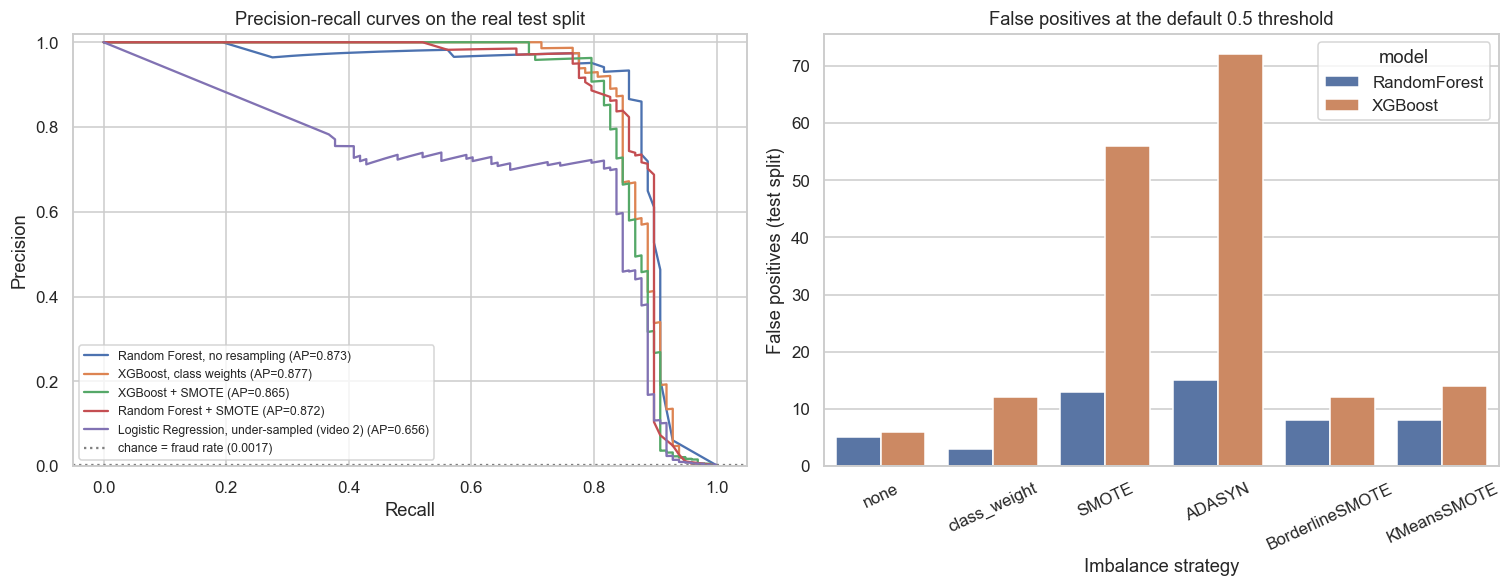

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
show = [("RandomForest__none", "Random Forest, no resampling"), ("XGBoost__class_weight", "XGBoost, class weights"),
        ("XGBoost__SMOTE", "XGBoost + SMOTE"), ("RandomForest__SMOTE", "Random Forest + SMOTE"),
        ("LogReg__undersample (video 2)", "Logistic Regression, under-sampled (video 2)")]
for key, label in show:
    p, r, _ = precision_recall_curve(y_test, P[key])
    ax[0].plot(r, p, label=f"{label} (AP={average_precision_score(y_test, P[key]):.3f})")
ax[0].axhline(y_test.mean(), color="gray", ls=":", label=f"chance = fraud rate ({y_test.mean():.4f})")
ax[0].set(title="Precision-recall curves on the real test split", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
ax[0].legend(fontsize=8, loc="lower left")

d = v1[v1.model.isin(["RandomForest", "XGBoost"])]
order = ["none", "class_weight", "SMOTE", "ADASYN", "BorderlineSMOTE", "KMeansSMOTE"]
sns.barplot(data=d, x="strategy", y="fp", hue="model", order=order, ax=ax[1])
ax[1].set(title="False positives at the default 0.5 threshold", xlabel="Imbalance strategy", ylabel="False positives (test split)")
ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

### Is any strategy actually better? A 98-fraud test set cannot tell

The test split has only 98 frauds, so a 0.01 PR-AUC gap is probably noise. Two checks: a bootstrap confidence interval on the test split, and 5-fold cross-validation (all 492 frauds pooled across test folds, resampling inside each training fold).

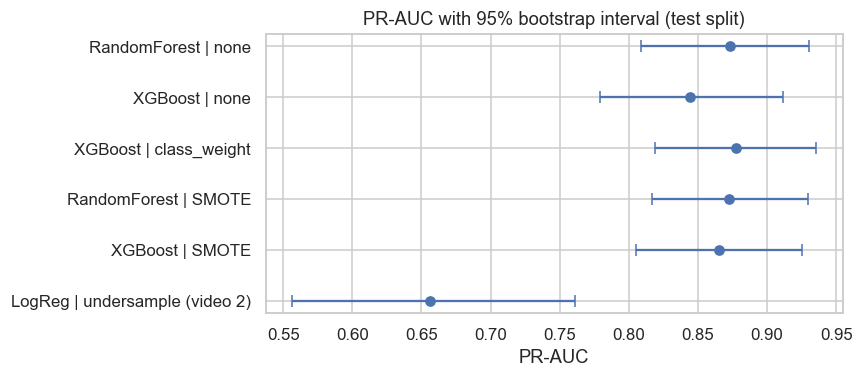

,model | strategy,PR-AUC,CI low,CI high
0,RandomForest | none,0.873,0.809,0.930
1,XGBoost | none,0.844,0.779,0.911
2,XGBoost | class_weight,0.877,0.819,0.936
3,RandomForest | SMOTE,0.872,0.817,0.930
4,XGBoost | SMOTE,0.865,0.805,0.925
5,LogReg | undersample (video 2),0.656,0.556,0.761


In [7]:
rng = np.random.RandomState(0)
keys = ["RandomForest__none", "XGBoost__none", "XGBoost__class_weight", "RandomForest__SMOTE", "XGBoost__SMOTE", "LogReg__undersample (video 2)"]
ci = []
for k in keys:
    vals = []
    for _ in range(500):
        i = rng.randint(0, len(y_test), len(y_test))
        if y_test[i].sum():
            vals.append(average_precision_score(y_test[i], P[k][i]))
    ci.append((k.replace("__", " | "), average_precision_score(y_test, P[k]), *np.percentile(vals, [2.5, 97.5])))
ci = pd.DataFrame(ci, columns=["model | strategy", "PR-AUC", "CI low", "CI high"])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(ci["PR-AUC"], range(len(ci)), xerr=[ci["PR-AUC"] - ci["CI low"], ci["CI high"] - ci["PR-AUC"]], fmt="o", capsize=4)
ax.set_yticks(range(len(ci))); ax.set_yticklabels(ci["model | strategy"]); ax.invert_yaxis()
ax.set(title="PR-AUC with 95% bootstrap interval (test split)", xlabel="PR-AUC")
plt.tight_layout(); plt.show()
ci.round(3)

In [8]:
cvt = pd.DataFrame({k: {"PR-AUC mean": v["pr_auc"]["mean"], "PR-AUC std": v["pr_auc"]["std"], "precision": v["precision"]["mean"],
                        "recall": v["recall"]["mean"], "F1": v["f1"]["mean"], "false pos. / fold": v["fp"]["mean"],
                        "false neg. / fold": v["fn"]["mean"]} for k, v in CV["summary"].items()}).T
cvt.index = [i.replace("|", " | ") for i in cvt.index]
cvt.sort_values("PR-AUC mean", ascending=False).round(4)

,PR-AUC mean,PR-AUC std,precision,recall,F1,false pos. / fold,false neg. / fold
XGBoost | class_weight,0.8570,0.0302,0.9130,0.8231,0.8655,7.8,17.4
RandomForest | SMOTE,0.8506,0.0313,0.8926,0.8272,0.8584,9.8,17.0
XGBoost | none,0.8487,0.0320,0.9396,0.7826,0.8535,5.0,21.4
XGBoost | SMOTE,0.8477,0.0285,0.6446,0.8475,0.7318,46.2,15.0
RandomForest | none,0.8450,0.0287,0.9489,0.7866,0.8600,4.2,21.0
LogReg | undersample (video 2),0.6644,0.0612,0.0410,0.9207,0.0785,2153.0,7.8


**5-fold cross-validation says:** the 5 tree-model configurations are statistically indistinguishable (PR-AUC 0.845 to 0.857, fold-to-fold standard deviation about 0.030). Resampling did **not** improve how well the models rank frauds above legitimate transactions. What it changed is the operating point: XGBoost with SMOTE has precision **0.645** and **46** false positives per fold, versus **0.913** and **8** with class weights, for a similar PR-AUC.

In [9]:
# Is the SMOTE gain just a threshold shift? Compare precision at matched recall (test split, XGBoost).
def precision_at_recall(key, target):
    p, r, _ = precision_recall_curve(y_test, P[key])
    return p[r >= target].max()

rec_smote = U["video1"][[ (r["model"], r["strategy"]) for r in U["video1"] ].index(("XGBoost", "SMOTE"))]["recall"]
out = pd.DataFrame({"precision at the same recall": {
    "XGBoost, no resampling": precision_at_recall("XGBoost__none", rec_smote),
    "XGBoost, class weights": precision_at_recall("XGBoost__class_weight", rec_smote),
    "XGBoost + SMOTE": precision_at_recall("XGBoost__SMOTE", rec_smote)}})
print(f"Recall target = {rec_smote:.3f} (the recall XGBoost + SMOTE reaches at threshold 0.5)")
out.round(3)

Recall target = 0.857 (the recall XGBoost + SMOTE reaches at threshold 0.5)


,precision at the same recall
"XGBoost, no resampling",0.241
"XGBoost, class weights",0.672
XGBoost + SMOTE,0.667


At the same recall (0.857), XGBoost + SMOTE and XGBoost with class weights reach almost identical precision (0.667 vs 0.672), so **SMOTE adds nothing over simply re-weighting the loss**. Plain XGBoost with no imbalance handling is much worse at this high-recall point (0.241). That is a tail-of-the-curve measure on only 98 frauds, so treat it as indicative. The cross-validated PR-AUCs above are within noise of each other, so the safe conclusion is only that SMOTE is not better than class weights, which is the cheaper option. The false-positive chart above shows the other side of SMOTE and ADASYN: at the default 0.5 threshold they flag far more transactions than class weights do.

### A leakage check

ULB contains repeated feature vectors. If the same row sits in both the training and test split, scores are inflated.

In [10]:
from fraud_pipeline.train_ulb import prepare, FEATURES
S = prepare(ulb)
h = pd.util.hash_pandas_object(ulb[FEATURES], index=False)
train_hashes = set(h.loc[S["Xtr"].index])
has_twin = h.loc[S["Xte"].index].isin(train_hashes).values
print(f"Test rows with an exact twin in the training split: {has_twin.sum():,} of {len(has_twin):,} ({100*has_twin.mean():.2f}%); frauds among them: {int(y_test[has_twin].sum())}")
for k in ["RandomForest__none", "XGBoost__class_weight", "LogReg__undersample (video 2)"]:
    keep = ~has_twin
    print(f"{k:34s} PR-AUC all test rows {average_precision_score(y_test, P[k]):.4f} | excluding twins {average_precision_score(y_test[keep], P[k][keep]):.4f}")

Test rows with an exact twin in the training split: 344 of 56,962 (0.60%); frauds among them: 8
RandomForest__none                 PR-AUC all test rows 0.8734 | excluding twins 0.8570
XGBoost__class_weight              PR-AUC all test rows 0.8773 | excluding twins 0.8638
LogReg__undersample (video 2)      PR-AUC all test rows 0.6563 | excluding twins 0.6131


Only 0.60 % of test rows have an exact twin in the training split, but excluding them lowers PR-AUC by roughly 0.01 to 0.04 (printed above), so the headline scores are slightly inflated by repeated rows. The ranking of methods is unchanged. A de-duplicated split would be the cleaner protocol.

## 4. Which features matter, on real data and on the 2023 data?

In [11]:
F = U["features"]
def top(imp, names, n=8):
    o = np.argsort(imp)[::-1][:n]
    return [f"{names[i]} ({imp[i]:.2f})" for i in o]
x23 = X23["xgboost_importance"]
cmp_ = pd.DataFrame({
    "ULB: Random Forest": top(np.array(U["importances"]["RandomForest|none"]), F),
    "ULB: XGBoost (class weights)": top(np.array(U["importances"]["XGBoost|class_weight"]), F),
    "2023: XGBoost": [f"{k} ({v:.2f})" for k, v in sorted(x23.items(), key=lambda kv: -kv[1])[:8]],
}, index=range(1, 9))
cmp_.index.name = "rank"
cmp_

,ULB: Random Forest,ULB: XGBoost (class weights),2023: XGBoost
rank,,,
1,V17 (0.17),V14 (0.57),V14 (0.65)
2,V14 (0.14),V4 (0.06),V4 (0.07)
3,V12 (0.13),V12 (0.05),V12 (0.03)
4,V10 (0.07),V8 (0.03),V8 (0.02)
5,V16 (0.07),V7 (0.02),V1 (0.02)
6,V11 (0.05),Amount (0.02),V3 (0.02)
7,V9 (0.03),V27 (0.02),V10 (0.01)
8,V4 (0.03),V13 (0.02),V17 (0.01)


`V14` is the top feature (or among the top three) in every model on both datasets, and `V12`, `V10`, `V4` and `V17` recur. `V` features are anonymised, so this says *which columns the models use*, not what they represent.

## 5. Cross-dataset transfer: do the two datasets share fraud signal?

Train on one dataset, score the **entire other dataset** (never seen in training), using `V1`–`V28` only, each dataset standardised with its own statistics (no labels used). A model that learned nothing transferable would score PR-AUC equal to the target's fraud rate.

In [12]:
t = pd.DataFrame(XD["rows"])
t["lift over chance"] = t["transfer_pr_auc"] / t["target_fraud_rate"]
t = t.rename(columns={"target_fraud_rate": "chance PR-AUC"})
print(f"Correlation of per-feature fraud-vs-legit mean gaps across the datasets: {XD['v_gap_correlation']:.3f}")
t[["train_on", "scored_on", "chance PR-AUC", "in_domain_pr_auc", "transfer_pr_auc", "transfer_roc_auc", "lift over chance"]].round(4)

Correlation of per-feature fraud-vs-legit mean gaps across the datasets: 0.918


,train_on,scored_on,chance PR-AUC,in_domain_pr_auc,transfer_pr_auc,transfer_roc_auc,lift over chance
0,ULB,2023,0.5000,0.8657,0.9582,0.9494,1.9165
1,2023,ULB,0.0017,1.0000,0.5279,0.9842,305.5841


A model trained **only on ULB** scores the 2023 data at PR-AUC **0.958** (chance 0.500, ROC-AUC 0.949). A model trained **only on the 2023 data** scores all of ULB at PR-AUC **0.528** against a chance level of 0.0017, a lift of about 306x (ROC-AUC 0.984), and the per-feature fraud-vs-legitimate gaps correlate at 0.92. The `V` columns carry largely the same fraud signal in both datasets. This is consistent with the 2023 data being generated from ULB-like statistics; it does not prove it, and it also shows that the 2023 dataset's near-perfect in-domain scores (PR-AUC ≈ 1.00) do not carry over to real data (≈ 0.53 for the transferred model, ≈ 0.85 for models trained on ULB itself).

## 6. Video 3: PaySim-style transactions (pipeline ready, real data not available)

Per the Kaggle listing and public write-ups (not verified here, since I could not download it), the dataset is about 186 MB with 6,362,620 rows, columns `step, type, amount, nameOrig, oldbalanceOrg, newbalanceOrig, nameDest, oldbalanceDest, newbalanceDest, isFraud, isFlaggedFraud`, and roughly 0.13 % fraud. It is hosted only on Kaggle and needs a login, so it could not be downloaded here. The training pipeline (`fraud_pipeline/train_paysim.py`) is written and was smoke-tested end to end on a small **synthetic** file with the same schema. That test only proves the code runs; no real-data result is claimed.

What the pipeline does: drops row-unique account names, keeps only transaction types that contain fraud, adds `hour`, `errorBalanceOrig` and `errorBalanceDest` features, and trains Logistic Regression (balanced), XGBoost (`scale_pos_weight`) and a Random Forest on a thinned set of legitimate rows, scoring all of them on an untouched stratified test split. The balance-error features are strong in this dataset but partly reflect how the simulator books balances, so the scores should be read with that in mind.

In [13]:
from fraud_pipeline.data import load_paysim
try:
    ps = load_paysim(nrows=5)
    print("PaySim file found, run: python -m fraud_pipeline.train_paysim")
except FileNotFoundError as e:
    print("PaySim data not present yet.\n", e)

PaySim data not present yet.
 PaySim dataset not found in ./data/. Download 'Fraud Detection Dataset' from https://www.kaggle.com/datasets/amanalisiddiqui/fraud-detection-dataset (needs a free Kaggle login), unzip it, and put the CSV (e.g. 'AIML Dataset.csv') in ./data/.


## 7. Trained models and scoring new transactions

| File | Model | Trained on |
|---|---|---|
| `models/ulb_xgboost_best.json` + `ulb_scaler.joblib` | XGBoost with class weights (best PR-AUC on the ULB split) | ULB training split |
| `models/ulb_logreg_undersample.joblib` | Logistic Regression, video 2 recipe | 788 under-sampled ULB rows |
| `models/cc2023_xgboost.json` + `cc2023_scaler.joblib` | XGBoost | 2023 training split |

Risk bands (0.25 / 0.50 / 0.75) are illustrative defaults, not calibrated thresholds. The Random Forests are not saved: fully grown forests on ~455k resampled rows are hundreds of MB, and `python -m fraud_pipeline.train_ulb` retrains them in a few minutes.

In [14]:
from fraud_pipeline.predict import score
sample = pd.concat([ulb.loc[S["Xte"].index][lambda d: d.Class == 1].head(6), ulb.loc[S["Xte"].index][lambda d: d.Class == 0].head(6)])
scored = score("ulb", sample)
scored[["Time", "Amount", "Class", "fraud_probability", "risk_band"]].round(3).reset_index(drop=True)

,Time,Amount,Class,fraud_probability,risk_band
0,57007.0,0.01,1,1.000,Critical
1,68207.0,1.00,1,1.000,Critical
2,75581.0,124.53,1,0.999,Critical
3,43494.0,24.90,1,0.973,Critical
4,41313.0,9.99,1,1.000,Critical
5,45541.0,1.00,1,1.000,Critical
6,160760.0,23.00,0,0.000,Low
7,19847.0,11.85,0,0.000,Low
8,88326.0,76.07,0,0.000,Low
9,141734.0,0.99,0,0.000,Low


## 8. Conclusions

1. **High accuracy on a balanced sample is not a fraud detector.** The video 2 recipe scores 94.4% on its balanced hold-out but, on the real distribution, produces 2,258 false alarms for 90 frauds found (precision 3.8%, PR-AUC 0.66).
2. **Tree ensembles reach PR-AUC ≈ 0.85 on real card data**, not 0.99 and not 0.94. Cross-validated: Random Forest 0.845, XGBoost 0.849, XGBoost with class weights 0.857 (± ~0.03). The 0.99998 PR-AUC on the 2023 dataset is a property of that dataset.
3. **SMOTE, ADASYN, Borderline-SMOTE and KMeans-SMOTE did not improve ranking quality** here (cross-validated PR-AUC within noise of the non-resampled models). They shifted the operating point toward more recall and more false positives: XGBoost + SMOTE has 46 false positives per fold versus 8 with class weights. At matched recall, SMOTE and class weights give the same precision, so class weights are the simpler choice that is at least as good in this experiment.
4. **The best single model on the ULB split is XGBoost with class weights** (PR-AUC 0.877), but the 95 % bootstrap interval is roughly ±0.06, so it is not demonstrably better than Random Forest.
5. **The 2023 and ULB datasets share fraud signal** (transfer PR-AUC 0.53 against chance 0.0017), which supports treating the 2023 data as ULB-like synthetic data.

### Limitations
- The ULB test split holds only 98 frauds; differences below about 0.03 PR-AUC are not reliable (hence the cross-validation).
- Random stratified splits, although ULB has a `Time` column; a time-ordered split would be a harder, more realistic test and was not run.
- No hyper-parameter search. Settings are sensible defaults.
- Video 1's AGSS sampler, LSTM and Flask app are not replicated; video 3's dataset was not available, so its results are pending.
- I could not watch the videos; replication follows their descriptions.